In [1]:
import jax
import jax.numpy as jnp
from flax import nnx

from hcnn.policy.policy_lqr import PolicyLQR
from hcnn.state_action_constraint.constraint_state_outside_sphere import StateOutsideSphere
from hcnn.system.system_linear import SystemLinear

center = jnp.array([1, 1])
radius = 1.25

state_matrix = jnp.array([[1, -1], [1, 0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemLinear.factory(state_matrix, input_matrix)
policy = PolicyLQR(system, state_cost, input_cost)
constraint = StateOutsideSphere.factory(center=center, radius=radius)
# environment = Environment.factory(system, policy, constraint)

In [8]:
graphdef, state = nnx.split(policy)
print(state)

leaves, treedef = jax.tree_util.tree_flatten(state)
print(treedef)

State({
  'gain_matrix': Array([[ 0.61014867, -0.75787866]], dtype=float32),
  'input_cost': Array([[1.]], dtype=float32),
  'riccati_matrix': Array([[ 3.1301594, -0.6101485],
         [-0.6101485,  1.7578782]], dtype=float32),
  'state_cost': Array([[1., 0.],
         [0., 1.]], dtype=float32),
  'test': VariableState( # 1 (4 B)
    type=Param,
    value=Array(1., dtype=float32, weak_type=True)
  )
})
PyTreeDef(CustomNode(State[('gain_matrix', 'input_cost', 'riccati_matrix', 'state_cost', 'test')], [*, *, *, *, CustomNode(VariableState[(<class 'flax.nnx.variablelib.Param'>, ())], [*])]))


In [3]:
nnx.display(policy)

In [ ]:
view_range = 5.0
samples_per_axis = 25
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
test = environment.step(jnp.array([1.0, 2.0]))
next_states = jax.vmap(environment.step, in_axes=(0))(states)
difference = next_states - states

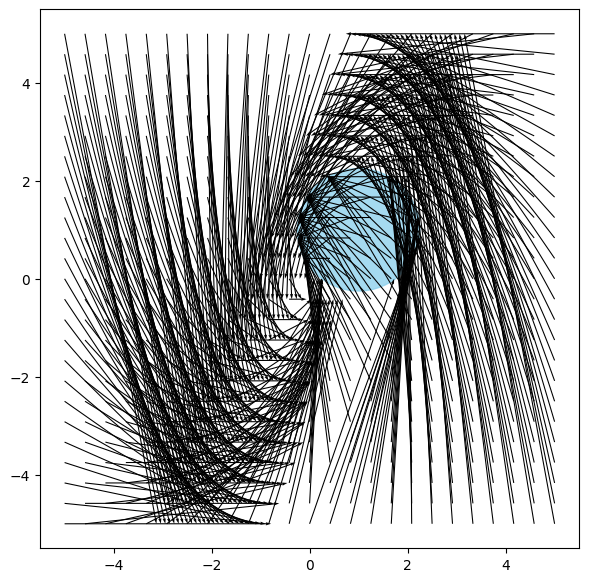

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.quiver(
    states[:, 0],
    states[:, 1],
    difference[:, 0],
    difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.002,
)
plt.show()

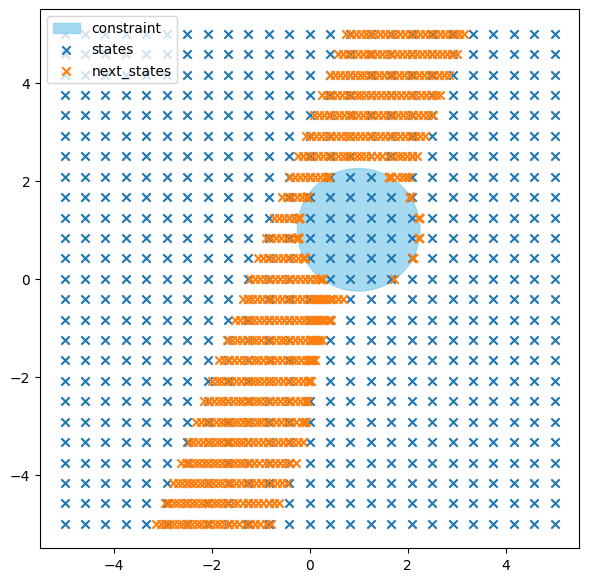

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.scatter(states[:, 0], states[:, 1], marker="x", label="states")
plt.scatter(next_states[:, 0], next_states[:, 1], marker="x", label="next_states")
plt.legend()
plt.show()

In [ ]:
from hcnn.optimization.problem_policy_deviation import ProblemPolicyDeviation

problem = ProblemPolicyDeviation.factory(
    system=system,
    policy=policy,
    constraint=constraint,
    horizon=10,
    rho=30,
).copy_with(initial_state=jnp.array([1.0, -1.0]))

problem.pretty_print(problem.x0)
print("cost", problem.cost_fun(problem.x0))
# print("lb", jnp.all(problem.lower_bound - 1e-6 <= problem.constraints(problem.x0)))
# print("ub", jnp.all(problem.constraints(problem.x0) <= problem.upper_bound + 1e-6))

actions [[-1.3680273e+00]
 [ 3.7228137e-01]
 [ 4.7636300e-01]
 [ 9.5573477e-02]
 [-7.8078195e-02]
 [-5.3579271e-02]
 [-1.9835520e-03]
 [ 1.2199394e-02]
 [ 5.2362108e-03]
 [-9.1239013e-04]]
policy_actions [[-1.3680273e+00]
 [ 3.7228137e-01]
 [ 4.7636300e-01]
 [ 9.5573477e-02]
 [-7.8078195e-02]
 [-5.3579271e-02]
 [-1.9835520e-03]
 [ 1.2199394e-02]
 [ 5.2362108e-03]
 [-9.1239013e-04]]
states [[ 1.         -1.        ]
 [ 0.6319727   1.        ]
 [ 0.00425404  0.6319727 ]
 [-0.15135562  0.00425404]
 [-0.06003619 -0.15135562]
 [ 0.01324124 -0.06003619]
 [ 0.01969816  0.01324124]
 [ 0.00447337  0.01969816]
 [-0.0030254   0.00447337]
 [-0.00226255 -0.0030254 ]]
relaxations [[0.       ]
 [1.4270558]
 [0.4355458]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]]
abs_relaxations [[0.       ]
 [1.4270558]
 [0.4355458]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]]
cost 27.939026


In [ ]:
x_star = environment.solver.solve(problem)
problem.pretty_print(x_star)
print("cost", problem.cost_fun(x_star))

actions [[-2.2505567 ]
 [ 0.9108014 ]
 [ 0.01733609]
 [-0.21368474]
 [-0.08752815]
 [ 0.01755632]
 [ 0.02798726]
 [ 0.0066822 ]
 [-0.00412361]
 [-0.0030212 ]]
policy_actions [[-1.3680319 ]
 [ 0.91075647]
 [ 0.01740822]
 [-0.21365568]
 [-0.08753648]
 [ 0.0175711 ]
 [ 0.02806653]
 [ 0.0067137 ]
 [-0.00420593]
 [-0.00335051]]
states [[ 1.0000039e+00 -9.9999529e-01]
 [-2.5055799e-01  9.9999297e-01]
 [-3.3975133e-01 -2.5055420e-01]
 [-7.1859948e-02 -3.3976737e-01]
 [ 5.4221138e-02 -7.1845211e-02]
 [ 3.8542211e-02  5.4215547e-02]
 [ 1.8850049e-03  3.8557332e-02]
 [-8.6797634e-03  1.8677269e-03]
 [-3.8682153e-03 -8.6675258e-03]
 [ 6.7369349e-04 -3.8900985e-03]]
relaxations [[-4.2191088e-05]
 [-5.3545402e-04]
 [ 3.0708188e-04]
 [ 1.2959375e-04]
 [ 1.9588588e-06]
 [-2.2755081e-05]
 [-3.2170833e-06]
 [-1.7206306e-05]
 [-7.9779282e-05]
 [ 5.6384157e-05]]
abs_relaxations [[ 3.5199562e-06]
 [-3.5291165e-12]
 [ 1.7492644e-11]
 [ 2.3689704e-13]
 [-1.7149132e-06]
 [ 5.4045272e-06]
 [ 1.9108095e-06]
 [

cost 0.38955027
lb True
ub True


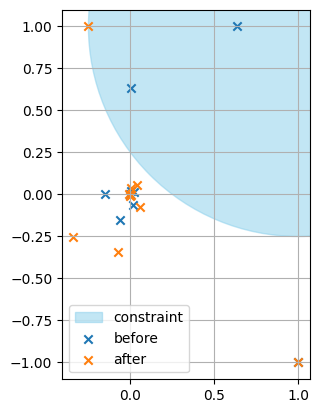

In [ ]:
print("cost", problem.cost_fun(x_star))
print("lb", jnp.all(problem.lower_bound - 1e-2 <= problem.constraints(x_star)))
print("ub", jnp.all(problem.constraints(x_star) <= problem.upper_bound + 1e-2))


optvar_star = problem.debug_optvar(x_star)
optvar_0 = problem.debug_optvar(problem.x0)

# Create figure and axis
fig, ax = plt.subplots()
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
plt.scatter(optvar_0.states[:, 0], optvar_0.states[:, 1], marker="x", label="before")
plt.scatter(optvar_star.states[:, 0], optvar_star.states[:, 1], marker="x", label="after")
ax.set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()